Detecção de transações suspeitas em dados bancários

Objetivo: identificar e priorizar transações suspeitas usando regras de negócio e o algoritmo Isolation Forest.

Dados: Bank Transaction Dataset for Fraud Detection (Kaggle), licença Apache 2.0. 2.512 transações de 495 contas.

Atenção: o dataset não tem coluna de fraude. Por isso o projeto cria critérios de risco e prioriza transações para revisão, em vez de treinar um modelo supervisionado.

Etapas: 
1. Limpeza e preparação
2. Análise exploratória
3. Sinais de risco
4. Resultados
5. Comparação com Isolation Forest
6. Conclusões e limitações

In [6]:
import pandas as pd

df = pd.read_csv("bank_transactions_data_2.csv")
print(df.shape)
df.head()


(2512, 16)


,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


1. Conhecendo a tabela

Antes de alterar qualquer coisa, confiro o tamanho da tabela, as colunas e o tipo de dado de cada uma.

In [7]:
print(df.shape)
df.info()

(2512, 16)
<class 'pandas.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   str    
 1   AccountID                2512 non-null   str    
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   str    
 4   TransactionType          2512 non-null   str    
 5   Location                 2512 non-null   str    
 6   DeviceID                 2512 non-null   str    
 7   IP Address               2512 non-null   str    
 8   MerchantID               2512 non-null   str    
 9   Channel                  2512 non-null   str    
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   str    
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBalance          

In [11]:
df_limpo = df.copy()

1.1 Limpeza e preparação

Coluna de "transação anterior" inconsistente. A coluna "PreviousTransactionDate" deveria ser anterior à data da transação. 

In [12]:
df_limpo["TransactionDate"] = pd.to_datetime(df_limpo["TransactionDate"])
df_limpo["PreviousTransactionDate"] = pd.to_datetime(df_limpo["PreviousTransactionDate"])

df_limpo[["TransactionDate", "PreviousTransactionDate"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   TransactionDate          2512 non-null   datetime64[us]
 1   PreviousTransactionDate  2512 non-null   datetime64[us]
dtypes: datetime64[us](2)
memory usage: 39.4 KB


In [15]:
inconsistentes = (df_limpo["PreviousTransactionDate"] > df_limpo["TransactionDate"]).sum()
print(f"Transações com 'data anterior' posterior à data da transação: {inconsistentes} de {len(df_limpo)}")

Transações com 'data anterior' posterior à data da transação: 2512 de 2512


Resultado: A coluna PreviousTransactionDate foi descartada por conter datas posteriores á própria transação. Ela não é confiável. Usar uma coluna com datas impossíveis levaria a conclusões erradas, como calcular “dias desde a última transação” e obter números negativos ou absurdos.

In [16]:
df_limpo = df_limpo.rename(columns={
    "TransactionID": "id_transacao",
    "AccountID": "id_conta",
    "TransactionAmount": "valor",
    "TransactionDate": "data_transacao",
    "TransactionType": "tipo",
    "Location": "cidade",
    "DeviceID": "id_dispositivo",
    "IP Address": "ip",
    "MerchantID": "id_comerciante",
    "Channel": "canal",
    "CustomerAge": "idade",
    "CustomerOccupation": "profissao",
    "TransactionDuration": "duracao",
    "LoginAttempts": "tentativas_login",
    "AccountBalance": "saldo",
})

df_limpo.columns

Index(['id_transacao', 'id_conta', 'valor', 'data_transacao', 'tipo', 'cidade',
       'id_dispositivo', 'ip', 'id_comerciante', 'canal', 'idade', 'profissao',
       'duracao', 'tentativas_login', 'saldo', 'PreviousTransactionDate'],
      dtype='str')

1.2 Criando colunas novas

Crio hora, ano_mes e dia_semana a partir da data da transação, e faixa_etaria, que agrupa a idade em quatro faixas. Elas permitem analisar por período e por perfil nas próximas etapas.

In [17]:
# Hora do dia (0 a 23)
df_limpo["hora"] = df_limpo["data_transacao"].dt.hour

# Mês no formato 2023-04
df_limpo["ano_mes"] = df_limpo["data_transacao"].dt.to_period("M")

# Dia da semana em português
dias = {0: "Segunda", 1: "Terça", 2: "Quarta", 3: "Quinta", 4: "Sexta", 5: "Sábado", 6: "Domingo"}
df_limpo["dia_semana"] = df_limpo["data_transacao"].dt.dayofweek.map(dias)

# Faixa etária
df_limpo["faixa_etaria"] = pd.cut(
    df_limpo["idade"],
    bins=[17, 29, 44, 59, 100],
    labels=["18-29", "30-44", "45-59", "60+"],
)

In [13]:
display(df_limpo.head())
df_limpo.info()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


<class 'pandas.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   TransactionID            2512 non-null   str           
 1   AccountID                2512 non-null   str           
 2   TransactionAmount        2512 non-null   float64       
 3   TransactionDate          2512 non-null   datetime64[us]
 4   TransactionType          2512 non-null   str           
 5   Location                 2512 non-null   str           
 6   DeviceID                 2512 non-null   str           
 7   IP Address               2512 non-null   str           
 8   MerchantID               2512 non-null   str           
 9   Channel                  2512 non-null   str           
 10  CustomerAge              2512 non-null   int64         
 11  CustomerOccupation       2512 non-null   str           
 12  TransactionDuration      2512 non-null   int6

1.3 Checagem para verificar se as faixas etárias estão cobrindo todo mundo. A soma deu 2.512, o que indica que está tudo certo.

In [18]:
df_limpo["faixa_etaria"].value_counts().sort_index()

faixa_etaria
18-29    759
30-44    479
45-59    663
60+      611
Name: count, dtype: int64

2. Preparar os gráficos 

Aqui foi usado o set_theme para aplciar um visual limpo. 

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

2.1 Visão geral das categorias

Começo contando quantas transações há em cada tipo, canal e profissão, para saber se os grupos são equilibrados ou se algum domina.

In [21]:
print("Tipo de transação (%):")
display((df_limpo["tipo"].value_counts(normalize=True) * 100).round(1))

print("\nCanal (quantidade):")
display(df_limpo["canal"].value_counts())

print("\nProfissão (quantidade):")
display(df_limpo["profissao"].value_counts())

Tipo de transação (%):


tipo
Debit     77.4
Credit    22.6
Name: proportion, dtype: float64


Canal (quantidade):


canal
Branch    868
ATM       833
Online    811
Name: count, dtype: int64


Profissão (quantidade):


profissao
Student     657
Doctor      631
Engineer    625
Retired     599
Name: count, dtype: int64

Os grupos são equilibrados. Débito representa 77,4% das transações e Crédito 22,6%; os três canais (Branch, ATM e Online) têm quantidades parecidas, entre 811 e 868.

2.2 Distribuição dos valores das transações

Antes de definir o que é um valor "alto", preciso entender como os valores se distribuem: a maioria é pequena? Existem valores muito distantes dos demais?

Para isso, uso:
- describe(), que resume os valores em números (média, mediana, mínimo, máximo e quartis);
- um histograma, que divide os valores em faixas e mostra quantas transações caem em cada uma. Barras altas indicam valores comuns, e barras baixas, valores raros.
- Comparo também a média com a mediana (o valor do meio). Se a média for bem maior, poucas transações de valor muito alto a estão puxando para cima.

count    2512.0
mean      297.6
std       291.9
min         0.3
25%        81.9
50%       211.1
75%       414.5
max      1919.1
Name: valor, dtype: float64

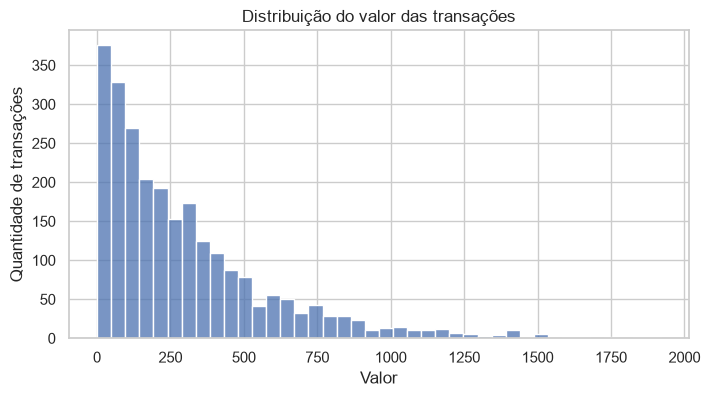

In [22]:
display(df_limpo["valor"].describe().round(1))

plt.figure(figsize=(8, 4))
sns.histplot(df_limpo["valor"], bins=40)
plt.title("Distribuição do valor das transações")
plt.xlabel("Valor")
plt.ylabel("Quantidade de transações")
plt.show()

Resultado: a média dos valores é de cerca de 298, bem maior que a mediana, de cerca de 211. O histograma mostra o motivo: há muitas transações pequenas e uma cauda longa à direita, que chega a 1.919. Poucas transações grandes puxam a média para cima.

Consequência: a média não é uma boa referência para definir "valor alto". Na Etapa 3, vou usar o IQR, método baseado em posições, que não é distorcido por esses valores extremos.

2.3 Valor das transações por grupo

Agora quero saber se algum perfil se comporta de forma diferente: clientes de um canal, tipo de transação, profissão ou faixa etária movimentam valores maiores que os demais? Se existir uma diferença clara, ela pode ser útil para definir os sinais de risco.
Para isso, vou usar:
- 'groupby', que separa a tabela em grupos (um por canal, por exemplo) e calcula medidas para cada grupo: quantidade, média e mediana;
- um boxplot para comparar os canais visualmente. Cada caixa mostra onde estão os 50% centrais dos valores; a linha dentro dela é a mediana, e os pontos acima são valores atípicos (muito distantes dos demais).

In [23]:
display(df_limpo.groupby("canal")["valor"].agg(["count", "mean", "median"]).round(1))
display(df_limpo.groupby("tipo")["valor"].agg(["count", "mean", "median"]).round(1))
display(df_limpo.groupby("profissao")["valor"].agg(["count", "mean", "median"]).round(1))
display(df_limpo.groupby("faixa_etaria", observed=True)["valor"].agg(["count", "mean", "median"]).round(1))


,count,mean,median
canal,,,
ATM,833,307.7,219.0
Branch,868,288.2,204.2
Online,811,297.2,206.6


,count,mean,median
tipo,,,
Credit,568,306.5,223.4
Debit,1944,295.0,205.1


,count,mean,median
profissao,,,
Doctor,631,292.7,199.1
Engineer,625,289.0,211.4
Retired,599,294.5,213.3
Student,657,313.2,215.9


,count,mean,median
faixa_etaria,,,
18-29,759,316.9,223.2
30-44,479,288.6,195.8
45-59,663,268.3,189.0
60+,611,312.5,230.1


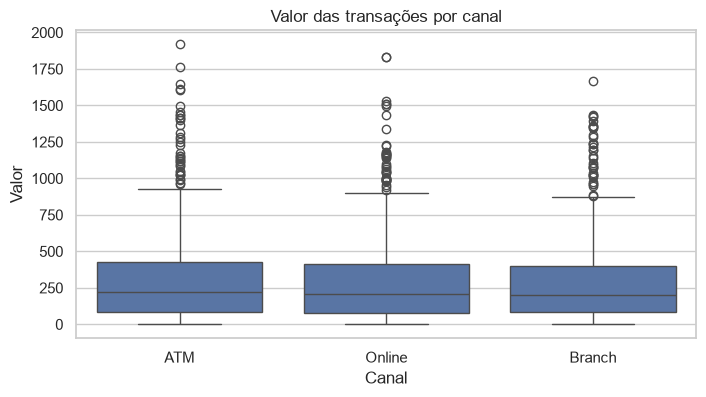

In [17]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_limpo, x="canal", y="valor")
plt.title("Valor das transações por canal")
plt.xlabel("Canal")
plt.ylabel("Valor")
plt.show()

Resultado: o valor médio é parecido entre os canais (ATM 307,7; Branch 288,2; Online 297,2), e os boxplots têm formatos semelhantes, com valores atípicos nos três. Não há diferença relevante entre canais.
Consequência: o canal sozinho não indica risco. Os sinais da Etapa 3 vão se basear no comportamento de cada transação (valor, saldo, login, dispositivo e duração), e não no canal usado.

2.4 Cidades com mais transações

Quero ver onde as transações se concentram. Como há muitas cidades, mostro só as 10 com mais transações; um gráfico com todas ficaria ilegível.

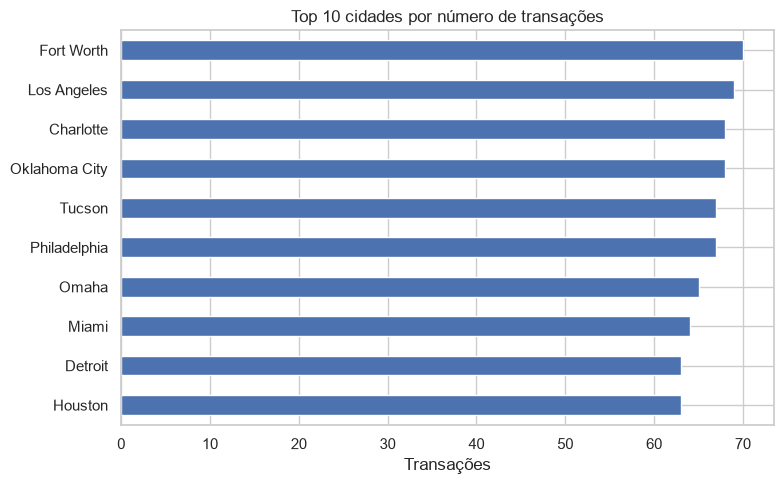

In [18]:
top_cidades = df_limpo["cidade"].value_counts().head(10)

plt.figure(figsize=(8, 5))
top_cidades.sort_values().plot(kind="barh")
plt.title("Top 10 cidades por número de transações")
plt.xlabel("Transações")
plt.ylabel("")
plt.tight_layout()
plt.show()

Resultado: Fort Worth (70), Los Angeles (69) e Oklahoma City (68) lideram, mas as diferenças entre as cidades são pequenas: nenhuma concentra uma fatia desproporcional das transações.
Consequência: cada cidade tem poucas transações, então qualquer comparação de risco entre cidades terá pouca confiança estatística.

2.5 Evolução no tempo

Vou olhar o calendário das transações de três ângulos: por mês, por dia da semana e por hora do dia. Padrões de calendário ajudam adefinir o que é normal e, às vezes, revelam problemas nos dados.

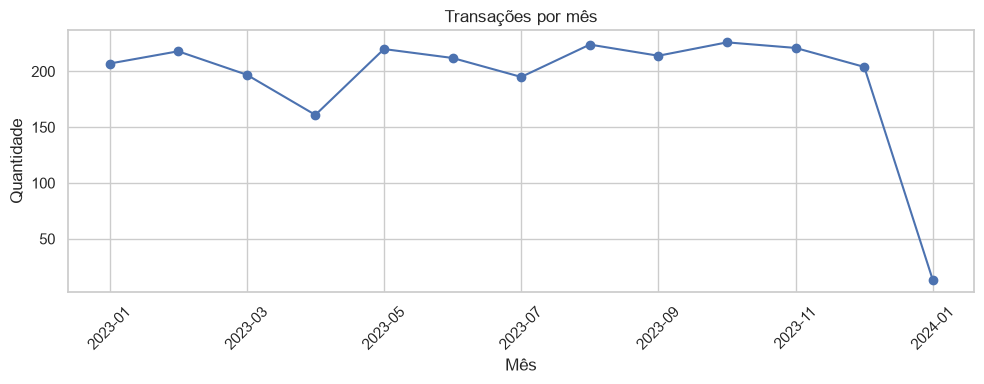

In [19]:
# Transações por mês
por_mes = df_limpo.groupby(df_limpo["ano_mes"].astype(str)).size()

plt.figure(figsize=(10, 4))
por_mes.plot(kind="line", marker="o")
plt.title("Transações por mês")
plt.xlabel("Mês")
plt.ylabel("Quantidade")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

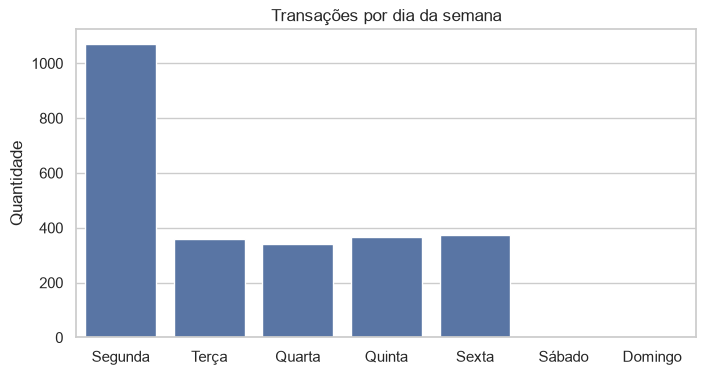

In [20]:
# Transações por dia da semana
ordem_dias = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]

plt.figure(figsize=(8, 4))
sns.countplot(data=df_limpo, x="dia_semana", order=ordem_dias)
plt.title("Transações por dia da semana")
plt.xlabel("")
plt.ylabel("Quantidade")
plt.show()

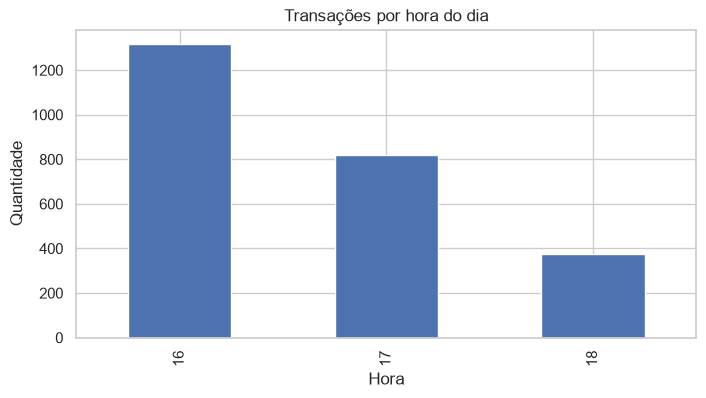

In [21]:
# Transações por hora
plt.figure(figsize=(8, 4))
df_limpo["hora"].value_counts().sort_index().plot(kind="bar")
plt.title("Transações por hora do dia")
plt.xlabel("Hora")
plt.ylabel("Quantidade")
plt.show()

Sobre o calendário:

- Hora: todas as transações ocorrem entre 16h e 18h59. Não há transações de madrugada ou de manhã.
- Dia da semana: só existem dias úteis, e a segunda-feira concentra cerca de 3 vezes mais transações que os outros dias (1.070 contra 340 a 370).
- Mês: abril tem menos transações que os demais, e janeiro de 2024 tem só 13, porque os dados terminam em 1º de janeiro.

Consequências:
- O sinal de "horário incomum" não faz sentido neste dataset. Ele será substituído por "duração incomum" na Etapa 3.

Correlação entre variáveis numéricas

A correlação mede se duas colunas "andam juntas", em uma escala de -1 a 1: perto de 0 significa que não há relação, e perto de 1 significa que sobem
juntas. Vou calculá-la para todas as colunas numéricas e mostrar o resultado num mapa de calor, em que cada quadrado mostra a correlação de um par de colunas.

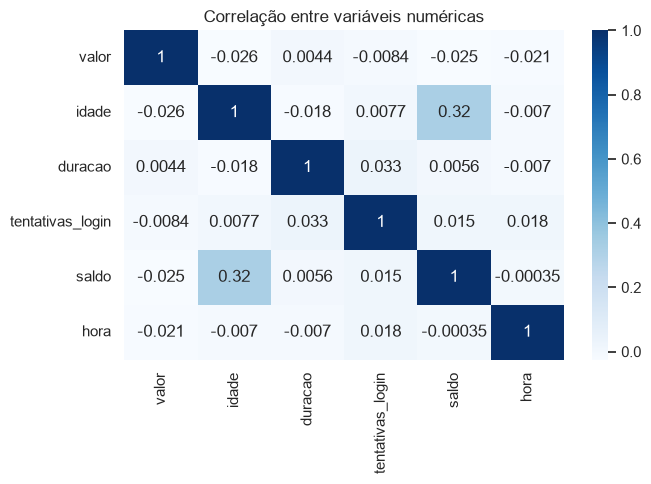

In [22]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_limpo.select_dtypes("number").corr(), annot=True, cmap="Blues")
plt.title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

Resultado: as correlações são quase nulas, com uma exceção: idade e saldo (cerca de 0,32), ou seja, clientes mais velhos tendem a ter saldo maior. Valor, duração e tentativas de login não se relacionam entre si.
Consequência: como as variáveis são pouco relacionadas, cada sinal da Etapa 3 traz informação própria. A relação entre idade e saldo ajudam a explicar um resultado da Etapa 4: o sinal "valor acima do saldo" dispara mais para os mais jovens, que têm saldo menor.

In [23]:
plt.savefig("images/distribuicao_valores.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

3. Sinais de risco

Como o dataset não diz quais transações são fraude, vou criar critérios objetivos de risco. Um sinal de riscomé uma característica que, sozinha, merece atenção, mas não prova fraude.
Cada sinal é uma pergunta de sim ou não feita a cada transação (por exemplo, "o valor está acima do saldo?") e fica guardado numa coluna de verdadeiro/falso. Depois, somo os sinais de cada transação: quanto mais sinais ativos, maior a pontuação de risco.
Um sinal isolado gera falsos alarmes (todo mundo erra a senha às vezes), mas vários sinais juntos tornam a transação bem menos provável de ser normal.

3.1 Muitas tentativas de login

Errar a senha várias vezes é um alerta clássico de acesso indevido. Vou marcar as transações com 3 ou mais tentativas de login. Escolhi 3 porque duas tentativas são comuns no dia a dia.

In [24]:
df_limpo["risco_login"] = df_limpo["tentativas_login"] >= 3
df_limpo["risco_login"].sum()

np.int64(95)

Resultado: 95 transações (3,8% do total) têm 3 ou mais tentativas de login.

3.2 Valor muito alto

Na Etapa 2, vimos que a média é distorcida por poucos valores altos, então ela não serve de régua. Vou usar o "IQR" (amplitude interquartil), que se
baseia em posições:
- q1 é o valor abaixo do qual estão 25% das transações, e q3, o valor abaixo do qual estão 75%;
- o iqr é a distância entre eles, o "miolo" dos dados;
- pela regra de bolso da estatística, valores acima de q3 + 1,5 × iqr são considerados atípicos.

In [25]:
q1 = df_limpo["valor"].quantile(0.25)
q3 = df_limpo["valor"].quantile(0.75)
iqr = q3 - q1
limite_alto = q3 + 1.5 * iqr

print(f"Limite para valor atípico: {limite_alto:.2f}")

df_limpo["risco_valor_alto"] = df_limpo["valor"] > limite_alto
df_limpo["risco_valor_alto"].sum()

Limite para valor atípico: 913.49


np.int64(113)

Resultado: o limite para valor atípico é de cerca de 913,50, e 113 transações (4,5%) o ultrapassam.

3.3 Valor maior que o saldo

Movimentar mais do que o saldo da conta merece atenção. Vou comparar o valor de cada transação com o saldo.

In [26]:
df_limpo["risco_acima_saldo"] = df_limpo["valor"] > df_limpo["saldo"]
df_limpo["risco_acima_saldo"].sum()

np.int64(119)

Resultado: 119 transações (4,7%) têm valor maior que o saldo.

3.4 Dispositivo usado por muitas contas

Um mesmo aparelho acessando muitas contas é um padrão típico de fraude. Para medir isso, conto quantas contas diferentes usaram cada dispositivo.
Escolha do limite: meu primeiro critério foi "mais de uma conta no mesmo dispositivo", mas ele marcava 97% das transações (609 dos 681
dispositivos têm mais de uma conta). Quando quase tudo é suspeito, o sinal não ajuda. Por isso, subi o limite para 8 ou mais contas.

In [27]:
contas_por_dispositivo = df_limpo.groupby("id_dispositivo")["id_conta"].transform("nunique")

df_limpo["risco_dispositivo"] = contas_por_dispositivo >= 8
df_limpo["risco_dispositivo"].sum()

np.int64(159)

Resultado: 159 transações (6,3%) usam dispositivos compartilhados por 8 ou mais contas. O limite é uma escolha minha e foi calibrado para que o sinal seja seletivo.

3.5 Duração incomum da transação

Como todas as transações ocorrem entre 16h e 18h59 (Etapa 2), o sinal de "horário incomum" não funciona neste dataset. Em seu lugar, vou marcar os 5% de transações mais rápidas e os 5% mais lentas: rapidez excessiva pode indicar automação, e demora excessiva, hesitação ou ajuda de terceiros.

In [28]:
p5 = df_limpo["duracao"].quantile(0.05)
p95 = df_limpo["duracao"].quantile(0.95)

df_limpo["risco_duracao"] = (df_limpo["duracao"] < p5) | (df_limpo["duracao"] > p95)
df_limpo["risco_duracao"].sum()

np.int64(243)

Resultado: o sinal marcou 243 transações (9,7%), 120 com duração abaixo de 24 segundos e 123 com duração acima de 265 segundos. Esse total já era esperado,
porque a regra escolhe os 5% mais rápidos e os 5% mais lentos, somando cerca de 10% das transações.
Por isso, é o sinal que marca mais transações entre os cinco. Isso é uma característica da regra, e não um indício de que as durações sejam mais suspeitas  que os outros sinais.

3.6 Pontuação e nível de risco

Agora somo os cinco sinais de cada transação. Como verdadeiro vale 1 e falso vale 0, a soma dá a pontuação (de 0 a 5). Em seguida, traduzo a pontuação em níveis:
0 | Baixo 
1 | Moderado 
2 | Alto 
3 ou mais | Crítico 

In [29]:
colunas_risco = [c for c in df_limpo.columns if c.startswith("risco_")]

df_limpo["pontuacao_risco"] = df_limpo[colunas_risco].sum(axis=1)

df_limpo["nivel_risco"] = pd.cut(
    df_limpo["pontuacao_risco"],
    bins=[-1, 0, 1, 2, 10],
    labels=["Baixo", "Moderado", "Alto", "Crítico"],
)

display(df_limpo["pontuacao_risco"].value_counts().sort_index())
display(df_limpo["nivel_risco"].value_counts().reindex(["Baixo", "Moderado", "Alto", "Crítico"]))

pontuacao_risco
0    1871
1     557
2      80
3       4
Name: count, dtype: int64

nivel_risco
Baixo       1871
Moderado     557
Alto          80
Crítico        4
Name: count, dtype: int64

Resultado: 1.871 transações têm risco Baixo, 557 Moderado, 80 Alto e 4 Crítico. A grande maioria é de baixo risco, e poucas transações merecem revisão prioritária. Nenhuma transação acumulou mais de 3 sinais.

3.7 Transações mais suspeitas

Ordeno as transações por pontuação e, em caso de empate, pelo valor, para ver quais um analista revisaria primeiro.

In [30]:
colunas_ver = ["id_transacao", "id_conta", "valor", "canal", "cidade", "pontuacao_risco", "nivel_risco"]

ranking = df_limpo.sort_values(["pontuacao_risco", "valor"], ascending=False)[colunas_ver]
display(ranking.head(10))

,id_transacao,id_conta,valor,canal,cidade,pontuacao_risco,nivel_risco
898,TX000899,AC00083,1531.31,Online,San Diego,3,Crítico
2272,TX002273,AC00268,1454.52,ATM,Miami,3,Crítico
274,TX000275,AC00454,1176.28,ATM,Kansas City,3,Crítico
291,TX000292,AC00284,1036.21,Online,Omaha,3,Crítico
1634,TX001635,AC00358,1762.28,ATM,Memphis,2,Alto
2414,TX002415,AC00028,1664.33,Branch,San Antonio,2,Alto
1247,TX001248,AC00071,1647.74,ATM,Louisville,2,Alto
1952,TX001953,AC00350,1496.57,Online,Memphis,2,Alto
2201,TX002202,AC00385,1431.54,Online,Portland,2,Alto
475,TX000476,AC00464,1431.30,ATM,Oklahoma City,2,Alto


Resultado: as 4 transações de nível Crítico têm valores entre 1.036 e 1.531, e as seguintes têm pontuação 2. Esse ranking será exportado para Excel na Etapa 4.

4. Resultados

Agora que cada transação tem uma pontuação de risco, vou responder a três perguntas: quanto risco existe, onde ele aparece e em quem se concentra.
Para simplificar, considero alto risco as transações com pontuação 2 ou mais (níveis Alto e Crítico).

4.0 Marcar as transações de alto risco

Crio uma coluna de verdadeiro/falso, alto_risco, para facilitar as contas de porcentagem: a média de uma coluna de verdadeiro/falso é a proporção
de verdadeiros.

In [31]:
import os
os.makedirs("images", exist_ok=True)

# Define "alto risco" como pontuação 2 ou mais (níveis Alto e Crítico)
df_limpo["alto_risco"] = df_limpo["pontuacao_risco"] >= 2

print(f"Transações de alto risco: {df_limpo['alto_risco'].sum()} "
      f"({df_limpo['alto_risco'].mean() * 100:.1f}% do total)")

Transações de alto risco: 84 (3.3% do total)


Resultado: 84 transações (3,3% do total) são de alto risco.

4.1 Quantas transações há em cada nível de risco

Para começar, quero ver a visão geral: como as transações se distribuem entre os quatro níveis (Baixo, Moderado, Alto e Crítico). Isso mostra se o critério é seletivo, isto é, se poucas transações são apontadas para revisão, ou se ele marca transações demais para ser útil.

Uso um gráfico de barras, com o número escrito em cima de cada uma.

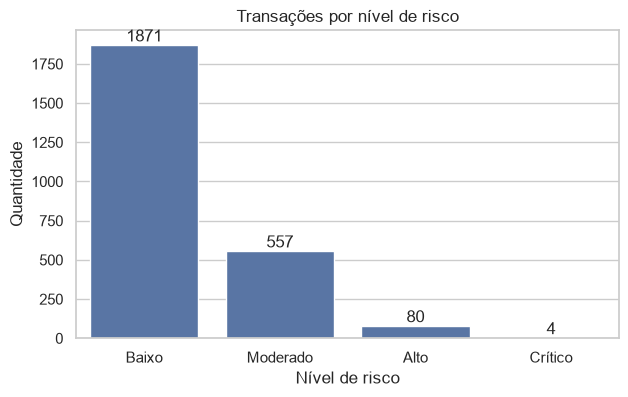

In [32]:
ordem_nivel = ["Baixo", "Moderado", "Alto", "Crítico"]

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df_limpo, x="nivel_risco", order=ordem_nivel, ax=ax)
ax.bar_label(ax.containers[0])
ax.set_title("Transações por nível de risco")
ax.set_xlabel("Nível de risco")
ax.set_ylabel("Quantidade")

fig.savefig("images/niveis_risco.png", dpi=150, bbox_inches="tight")
plt.show()

Resultado: a grande maioria das transações é de risco Baixo (1.871) ou Moderado (557). Só 80 são de risco Alto e 4 de risco Crítico, ou seja, o critério é seletivo: poucas transações merecem revisão prioritária.

4.2 Transações marcadas por cada sinal

Vou mostrar quantas transações cada um dos cinco sinais marca. Isso ajuda a conferir que nenhum sinal marca quase tudo (inútil) ou quase nada.

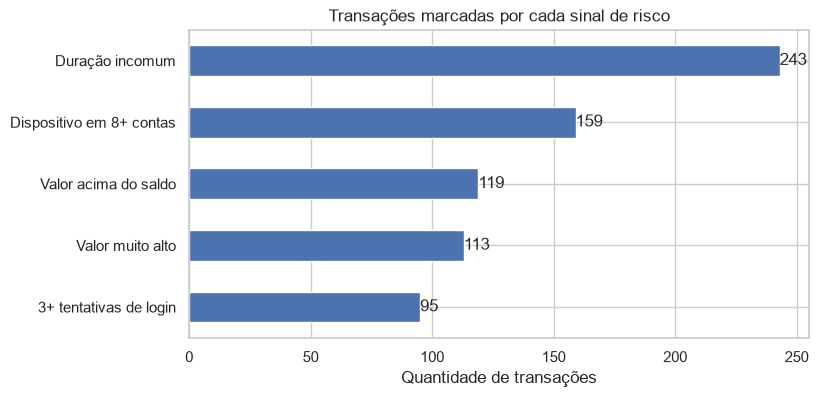

In [33]:
nomes = {
    "risco_login": "3+ tentativas de login",
    "risco_valor_alto": "Valor muito alto",
    "risco_acima_saldo": "Valor acima do saldo",
    "risco_dispositivo": "Dispositivo em 8+ contas",
    "risco_duracao": "Duração incomum",
}

colunas_risco = [c for c in df_limpo.columns if c.startswith("risco_")]
sinais = df_limpo[colunas_risco].sum().rename(index=nomes).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
sinais.plot(kind="barh", ax=ax)
ax.bar_label(ax.containers[0])
ax.set_title("Transações marcadas por cada sinal de risco")
ax.set_xlabel("Quantidade de transações")

fig.savefig("images/sinais_risco.png", dpi=150, bbox_inches="tight")
plt.show()

Resultado: os sinais marcam entre 95 (login) e 243 (duração) transações. Nenhum marca quase tudo ou quase nada. O sinal de duração marca mais porque a regra, por construção, seleciona cerca de 10% das transações.

4.3 Onde o risco se concentra: canal, profissão e idade

Vou calcular, para cada grupo, a porcentagem de transações de alto risco. Como os três gráficos têm a mesma estrutura, crio uma função que desenha o gráfico para qualquer coluna e a uso três vezes.

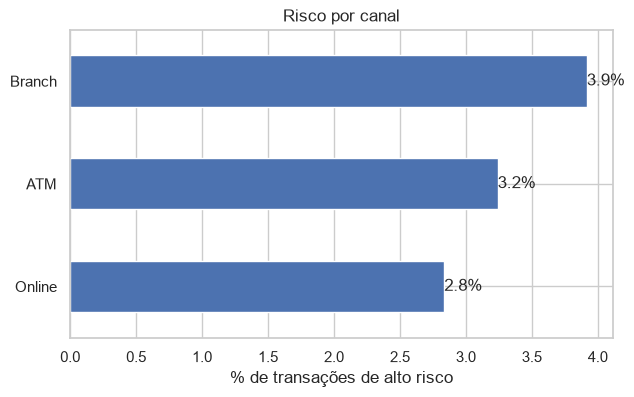

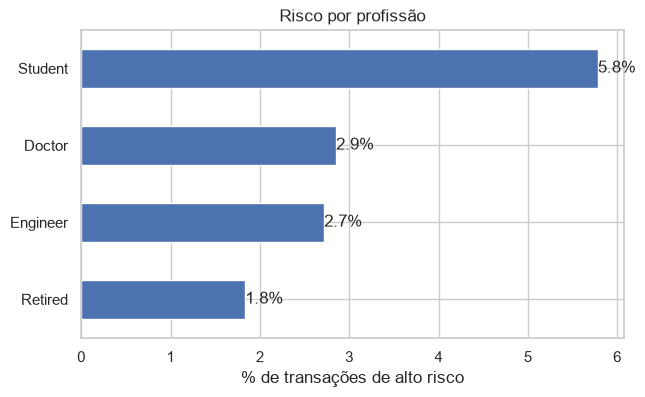

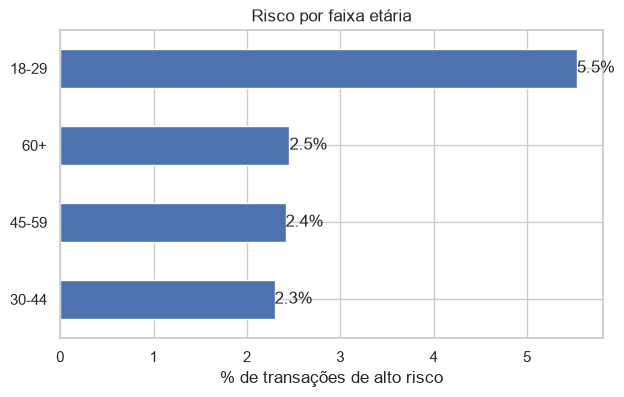

In [34]:
def grafico_risco(coluna, titulo, arquivo):
    pct = (df_limpo.groupby(coluna, observed=True)["alto_risco"].mean() * 100).sort_values()

    fig, ax = plt.subplots(figsize=(7, 4))
    pct.plot(kind="barh", ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%")
    ax.set_title(titulo)
    ax.set_xlabel("% de transações de alto risco")
    ax.set_ylabel("")

    fig.savefig(f"images/{arquivo}", dpi=150, bbox_inches="tight")
    plt.show()

grafico_risco("canal", "Risco por canal", "risco_canal.png")
grafico_risco("profissao", "Risco por profissão", "risco_profissao.png")
grafico_risco("faixa_etaria", "Risco por faixa etária", "risco_faixa_etaria.png")

Resultado:
- Canal: o alto risco varia entre 2,8% (Online) e 3,9% (Branch). A diferença é pequena e pode ser acaso; não há diferença relevante entre canais.
- Profissão: estudantes têm 5,8% de alto risco, bem acima das demais (Doctor 2,9%, Engineer 2,7% e Retired 1,8%).
- Faixa etária: a faixa de 18 a 29 anos tem 5,5%, contra 2,3% a 2,5% nas demais.

Interpretação: o destaque de estudantes e jovens provavelmente vem do saldo, e não de um comportamento mais arriscado. O saldo médio dos estudantes é de cerca de 1.570, contra 4.500 a 9.000 nas outras profissões, e o da faixa de 18 a 29 anos é de cerca de 2.200, contra 6.000 a 7.200 nas demais. Com saldo menor, o sinal "valor acima do saldo" dispara com mais facilidade. O resultado reflete como o sinal foi construído, e não que jovens sejam mais fraudulentos.

4.4 Risco por cidade

Com 43 cidades, um gráfico ficaria poluído, então uso uma tabela com o total de transações, quantas são de alto risco e a porcentagem. Mostrar o total permite ver o tamanho de cada amostra.

In [35]:
por_cidade = df_limpo.groupby("cidade").agg(
    total=("id_transacao", "size"),
    alto_risco=("alto_risco", "sum"),
    pct=("alto_risco", "mean"),
)
por_cidade["pct"] = (por_cidade["pct"] * 100).round(1)

display(por_cidade.sort_values("pct", ascending=False).head(10))

,total,alto_risco,pct
cidade,,,
Las Vegas,55,5,9.1
Miami,64,5,7.8
Washington,48,3,6.2
Phoenix,55,3,5.5
Indianapolis,58,3,5.2
San Diego,59,3,5.1
Jacksonville,60,3,5.0
Albuquerque,41,2,4.9
Houston,63,3,4.8


Atenção: cada cidade tem entre 41 e 70 transações. Las Vegas aparece no topo com 9,1%, mas isso equivale a apenas 5 transações de alto risco em 55; Miami tem 7,8% (5 de 64) e Nashville, 0% (nenhuma em 55). Com amostras tão pequenas, uma ou duas transações mudam o ranking, então ele é instável e não sustenta conclusões sobre cidades.

4.5 Contas com mais transações de risco

Uma equipe de análise costuma investigar contas, e não transações isoladas. Vou agrupar por conta para ver quais concentram mais transações de alto risco.

In [36]:
por_conta = df_limpo.groupby("id_conta").agg(
    transacoes=("id_transacao", "size"),
    alto_risco=("alto_risco", "sum"),
    pontuacao_media=("pontuacao_risco", "mean"),
).round(2)

display(por_conta.sort_values(["alto_risco", "pontuacao_media"], ascending=False).head(10))

,transacoes,alto_risco,pontuacao_media
id_conta,,,
AC00205,4,2,1.00
AC00108,6,2,0.83
AC00071,8,2,0.75
AC00465,8,2,0.75
AC00331,7,2,0.71
AC00217,6,2,0.67
AC00228,8,2,0.62
AC00385,7,2,0.57
AC00198,2,1,1.50


Resultado: 76 das 495 contas têm pelo menos uma transação de alto risco, e só 8 têm duas (por exemplo, AC00205, com 2 em 4 transações). Nenhuma conta tem mais de duas, então o risco está espalhado, e não concentrado em poucas contas.

4.6 A pontuação funciona?

Para conferir, calculo a média de valor, saldo e tentativas de login em cada nível. Se a pontuação faz sentido, o valor médio deve subir e o
saldo médio deve cair conforme o nível aumenta.

In [37]:
display(df_limpo.groupby("nivel_risco", observed=True)[["valor", "saldo", "tentativas_login"]].mean().round(1))

,valor,saldo,tentativas_login
nivel_risco,,,
Baixo,248.4,5390.0,1.0
Moderado,399.0,4547.9,1.4
Alto,691.7,2830.0,1.8
Crítico,1299.6,712.5,2.8


Resultado: o valor médio sobe de cerca de 248 (Baixo) para 1.300 (Crítico), e o saldo médio cai de cerca de 5.390 para 712. As tentativas de login também crescem (de 1,0 para 2,8). A pontuação se comporta como esperado.
Observação: Como valor, saldo e login compõem a pontuação, este resultado confirma a coerência do critério, não sua eficácia contra fraude.

5. Segunda opinião: Isolation Forest

Até aqui, eu disse ao programa o que é suspeito, por meio de regras escritas por mim. Nesta etapa, uso um algoritmo que faz o contrário: o Isolation Forest descobre sozinho quais transações são "estranhas", sem receber nenhuma definição de fraude.
O algoritmo faz cortes aleatórios nos dados para tentar isolar cada transação. Transações comuns, no meio da multidão, exigem muitos cortes. Transações incomuns, afastadas das demais, são isoladas rapidamente. Quanto mais rápido uma transação é isolada, mais anômala ela é.
Como o modelo não sabe o que é fraude, o resultado dele não é uma prova: é uma segunda opinião, independente das minhas regras. O objetivo é
comparar os dois métodos: onde concordam, a suspeita é mais forte.

In [38]:
colunas_ver = ["id_transacao", "id_conta", "valor", "canal", "cidade", "pontuacao_risco", "nivel_risco"]

ranking = df_limpo.sort_values(["pontuacao_risco", "valor"], ascending=False)[colunas_ver]
ranking.head(50).to_excel("ranking_suspeitas.xlsx", index=False)

In [39]:
from sklearn.ensemble import IsolationForest

5.1 Variáveis de entrada

O modelo só trabalha com números, então uso as colunas numéricas: valor, saldo, idade, duração e tentativas de login.
Crio também uma variável nova, valor_sobre_saldo (o valor dividido pelo saldo), que diz que fração do saldo a transação representa. Ela é mais informativa do que olhar valor e saldo separados: 500 de valor é pouco para quem tem saldo de 10.000, mas é muito para quem tem 200.

In [40]:
df_limpo["valor_sobre_saldo"] = df_limpo["valor"] / df_limpo["saldo"]

variaveis = ["valor", "saldo", "idade", "duracao", "tentativas_login", "valor_sobre_saldo"]
X = df_limpo[variaveis]

5.2 Treinar o modelo

Os parâmetros do modelo são escolhas minhas:
- contamination=0.05: informo ao modelo que espero cerca de 5% de anomalias. Com outro valor, o resultado muda.
- n_estimators=200: número de "árvores" de cortes aleatórios; mais árvores deixam o resultado mais estável.
- random_state=42: fixa o sorteio dos cortes, para o resultado ser sempre o mesmo (e reproduzível por quem rodar o projeto).
O modelo gera duas colunas: anomalia_modelo (verdadeiro ou falso) e score_anomalia, uma nota de quão estranha é a transação (quanto maior, mais anômala).

In [41]:
modelo = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)

df_limpo["anomalia_modelo"] = modelo.fit_predict(X) == -1
df_limpo["score_anomalia"] = -modelo.score_samples(X)

print(f"Anomalias apontadas pelo modelo: {df_limpo['anomalia_modelo'].sum()}")

Anomalias apontadas pelo modelo: 126


Resultado: o modelo apontou 126 transações (5%). Esse total não é uma descoberta: ele foi definido por mim ao escolher contamination=0.05. O que o modelo decide são quais transações compõem esses 5%, e não quantas.

5.3 Modelo × regras

Agora cruzo as duas classificações. Cada transação cai em um de quatro grupos:
- Os dois concordam: alto risco pelas regras e anomalia pelo modelo;
- Só as regras: alto risco pelas regras, mas normal para o modelo;
- Só o modelo: anomalia para o modelo, mas não é alto risco pelas regras;
- Nenhum dos dois: normal para ambos.
Como o dataset não tem rótulo de fraude, a concordância entre métodos independentes é a forma de validação que tenho.

In [42]:
display(pd.crosstab(df_limpo["alto_risco"], df_limpo["anomalia_modelo"],
                    rownames=["Regras: alto risco"], colnames=["Modelo: anomalia"]))

Modelo: anomalia,False,True
Regras: alto risco,,
False,2351,77
True,35,49


In [43]:
df_limpo["concordancia"] = "Nenhum dos dois"
df_limpo.loc[df_limpo["alto_risco"] & ~df_limpo["anomalia_modelo"], "concordancia"] = "Só as regras"
df_limpo.loc[~df_limpo["alto_risco"] & df_limpo["anomalia_modelo"], "concordancia"] = "Só o modelo"
df_limpo.loc[df_limpo["alto_risco"] & df_limpo["anomalia_modelo"], "concordancia"] = "Os dois concordam"

display(df_limpo["concordancia"].value_counts())

concordancia
Nenhum dos dois      2351
Só o modelo            77
Os dois concordam      49
Só as regras           35
Name: count, dtype: int64

Resultado:
- 49 transações são apontadas pelos dois métodos;
- 77 só pelo modelo e 35 só pelas regras;
- 2.351 por nenhum dos dois.

O modelo confirma 58% das transações de alto risco das regras (49 de 84). Ele não marcou nenhuma das 1.871 transações de risco Baixo, e marcou 46 das
80 de risco Alto e 3 das 4 de risco Crítico. Os dois métodos são coerentes.

Por que discordam:
- As 77 "só do modelo" têm todas pontuação 1 (um único sinal), mas uma combinação incomum. Em 44 delas o sinal ativo é o de login, e o modelo as destaca porque, além das tentativas de login, o valor também é alto (média de 577, contra 273 nas normais).
- As 35 "só das regras" incluem 22 marcadas por dispositivo compartilhado, informação que o modelo nem recebe como variável.

Discordar é útil: um método vê o que o outro não vê. Nenhum substitui o outro.

5.4 Visualizar a comparação

Cada ponto do gráfico é uma transação, com o valor no eixo horizontal e o saldo no vertical, colorida pelo grupo de concordância. Os pontos "os dois concordam" são desenhados por cima, para ficarem visíveis.

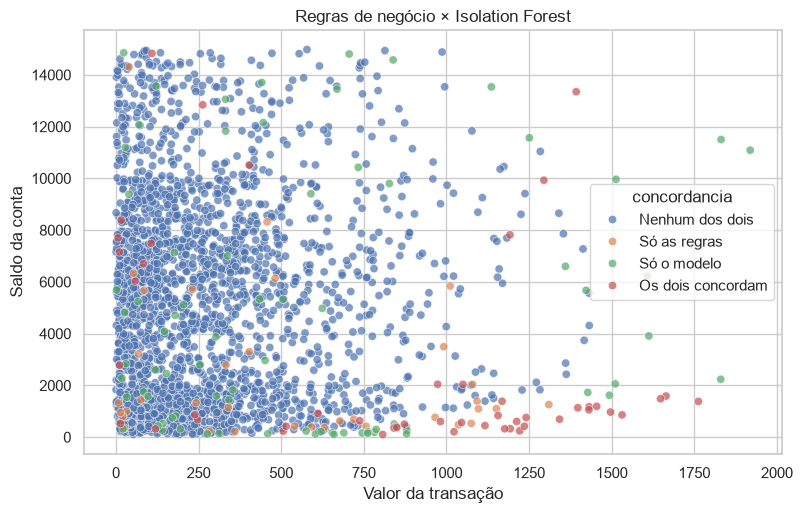

In [44]:
ordem = ["Nenhum dos dois", "Só as regras", "Só o modelo", "Os dois concordam"]
df_plot = df_limpo.sort_values("concordancia", key=lambda s: s.map({o: i for i, o in enumerate(ordem)}))

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=df_plot, x="valor", y="saldo", hue="concordancia",
                hue_order=ordem, alpha=0.7, ax=ax)
ax.set_title("Regras de negócio × Isolation Forest")
ax.set_xlabel("Valor da transação")
ax.set_ylabel("Saldo da conta")

fig.savefig("images/comparacao_regras_modelo.png", dpi=150, bbox_inches="tight")
plt.show()

Resultado: as transações em que os dois métodos concordam têm valor mediano de cerca de 1.023 e saldo médio de cerca de 2.934, contra um valor mediano de 202 e saldo médio de 5.210 nas transações que nenhum dos dois marcou. Em geral, valores altos com saldo baixo são os casos mais consensuais.

5.5 Transações para revisão prioritária

Separo as transações em que os dois métodos concordam e as ordeno pela nota de anomalia. É a suspeita mais forte do projeto: duas abordagens independentes chegaram à mesma conclusão.

In [45]:
prioridade = df_limpo[df_limpo["concordancia"] == "Os dois concordam"].sort_values(
    "score_anomalia", ascending=False
)

colunas_ver = ["id_transacao", "id_conta", "valor", "saldo", "canal", "pontuacao_risco", "score_anomalia"]
display(prioridade[colunas_ver].head(10).round(2))

prioridade[colunas_ver].round(2).to_excel("prioridade_revisao.xlsx", index=False)

,id_transacao,id_conta,valor,saldo,canal,pontuacao_risco,score_anomalia
274,TX000275,AC00454,1176.28,323.69,ATM,3,0.73
898,TX000899,AC00083,1531.31,859.86,Online,3,0.70
394,TX000395,AC00326,6.30,7697.68,Branch,2,0.67
2273,TX002274,AC00357,806.97,102.20,Online,2,0.67
934,TX000935,AC00456,1022.75,207.74,Branch,2,0.67
311,TX000312,AC00285,1221.65,243.92,Online,2,0.67
1213,TX001214,AC00170,1192.20,7816.41,Branch,2,0.66
1557,TX001558,AC00245,262.43,12841.01,Online,2,0.66
147,TX000148,AC00161,514.95,421.93,Online,2,0.65
375,TX000376,AC00316,1392.54,13347.69,Branch,2,0.64


Resultado: 49 transações formam a lista de prioridade. No topo estão a TX000275 (valor de 1.176 com saldo de 324 e 5 tentativas de login) e a TX000899 (valor de 1.531 com saldo de 860 e 4 tentativas de login).
Esta lista é um ponto de partida para revisão humana, e não uma conclusão de fraude: sem rótulos reais, não é possível medir quantas dessas transações são, de fato, fraudulentas.

O que esta etapa mostra e o que não mostra

- Mostra: regras e modelo se complementam, e a concordância entre eles permite priorizar a revisão.
- Não mostra: acurácia. Sem rótulo de fraude, não há como dizer "o modelo acertou X%". O que se mede é a concordância entre métodos.
- Escolhas minhas que mudam o resultado: contamination, a lista de variáveis e o limite de cada sinal de risco.

6. Conclusão geral

Objetivo: identificar e priorizar transações suspeitas em um dataset bancário sem rótulo de fraude, usando regras de negócio e o algoritmo Isolation Forest.

Principais resultados

- Critério de risco:cinco sinais (tentativas de login, valor muito alto, valor acima do saldo, dispositivo compartilhado e duração incomum) geraram uma pontuação para cada uma das 2.512 transações. 84 delas (3,3%) foram classificadas como de alto risco.
- Segunda opinião: o Isolation Forest apontou 126 transações (5%, valor definido por mim). Em 49 delas, regras e modelo concordam: essa é a lista de prioridade para revisão.
- Coerência: o modelo confirma 58% das transações de alto risco das regras e não marcou nenhuma das 1.871 de risco Baixo.
- Perfis: não há diferença relevante de risco entre canais. Estudantes e clientes de 18 a 29 anos aparecem acima da média, provavelmente porque têm saldo menor e o sinal "valor acima do saldo" dispara mais para eles.

Limitações

- O dataset é sintético (só dias úteis, horários entre 16h e 18h59, segunda-feira com 3 vezes mais transações).
- Não há rótulo de fraude, então não é possível medir acurácia. A validação é pela concordância entre métodos.
- A coluna PreviousTransactionDate foi descartada por conter datas posteriores às próprias transações.
- Os limites dos sinais (por exemplo, 8 ou mais contas por dispositivo) e o parâmetro contamination são escolhas minhas e mudam o resultado.
- A unidade da coluna de duração não é documentada (provavelmente segundos).
- Cada cidade tem poucas transações (41 a 70), então comparações por cidade são instáveis.

Próximos passos

- Validar os critérios com dados rotulados de fraude real.
- Calcular o intervalo entre transações de cada conta a partir da data da transação, novo sinal possível.
- Testar outros valores de contamination e outros algoritmos de detecção de anomalias.